In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

from src.selflensing.gp import TESSGP

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x11e826cf0>

In [3]:
LENSING_METHOD = 'IntegratedWittMao'

In [4]:
sls = SelfLensingSystem(
    a=20 * units.AU,
    i=0.5*numpy.pi * units.rad,
    Macc=10*units.M_sun,
    Mcomp=5 * units.M_sun,
    e=0 * units.dimensionless_unscaled,
    d=100*units.kpc,
)
sls.Rcomp, sls.Tmag, sls.Teff, sls.porb, sls.tau_eff, sls.b, sls.b_max, sls.rE(), sls.i, sls.tau_eff

(Quantity(Array(3.6238983, dtype=float32), unit='solRad'),
 Array(19.611223, dtype=float32),
 Quantity(Array(12397.592, dtype=float32), unit='K'),
 Quantity(Array(8435.247, dtype=float32), unit='d'),
 Quantity(Array(2.6397655, dtype=float32), unit='d'),
 Quantity(Array(0.00031111, dtype=float32), unit=''),
 Quantity(Array(6.997292, dtype=float32), unit=''),
 Quantity(Array(4.2038074e+08, dtype=float32), unit='m'),
 Quantity(Array(1.5707964, dtype=float32), unit='rad'),
 Quantity(Array(2.6397655, dtype=float32), unit='d'))

In [5]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-05")
peak_time = Time("2025-01-03")

In [6]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, gp=TESSGP, bins=27*24*6)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

In [7]:
min(lcg.lensing_system.time_to_b(lcg.time_offsets))

Array(0.00274547, dtype=float32)

In [8]:
lcg.lensing_system.time_to_phase([0]*units.day)

Quantity(Array([0.], dtype=float32), unit='rad')

In [9]:
lcg.lensing_system.phase_to_b(numpy.array([0]) * units.rad)

Array([0.00031111], dtype=float32)

In [10]:
lcg.lensing_system.time_to_b([0] * units.day)

Array([0.00031111], dtype=float32)

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>


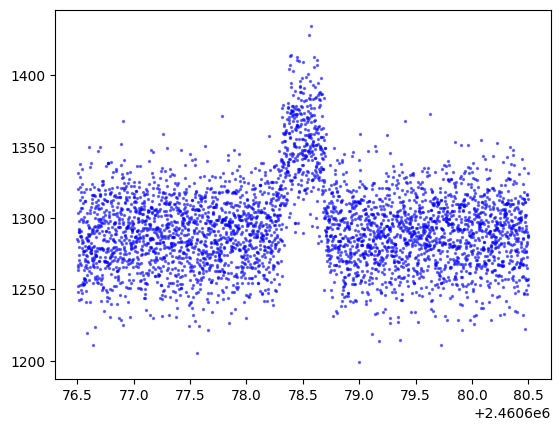

In [11]:
pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5, c='blue')

In [12]:
# gp_theta, sampler = tgp.fit()
# gp_theta

In [13]:
# max(sampler.get_log_prob(flat=True))

In [14]:
# import jax

# from src.selflensing.gp import LensingGP as lgp
# mag_lc = lgp.build_model_additive(
#     gp_theta, 
#     5, 
#     lgp.make_kernel_fn('GS'), 
#     lcg.time_offsets, 
#     include_lens_mean=0, 
#     noise_measure=tgp.noise_measure,
# )
# mag_samp = mag_lc.sample(jax.random.PRNGKey(tgp.seed))

# plt=pyplot
# # Plot the noise-only model
# plt.figure()
# # plt.errorbar(TESS_times_27/(24 * 60 * 60), noise_samp, yerr=noise_measure, ls = 'none', color = 'grey')
# plt.plot(lcg.times.jd, mag_samp, label='Noise-only model', marker ='o', markersize=2, linestyle = 'None', color='black', alpha=0.5)
# plt.xlabel('Time [days]')
# plt.ylabel('Flux')
# plt.show()

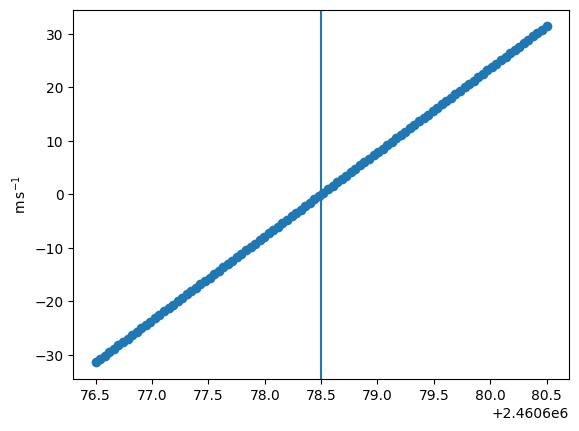

In [15]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.axvline(peak_time.jd)

## Orbital period detection

In [16]:
# import numpy
# peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
# min_mag = peak_mag * 0.999
# max_mag = peak_mag * 1.001
# min_mag, peak_mag, max_mag

In [17]:
# non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [18]:
# from src.selflensing.porb import estimate_porb

# p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
# p

In [19]:
# from astropy import units
# bin_starts = units.Quantity(p[0])
# bin_ends = units.Quantity(p[1])
# bin_counts = numpy.array(p[2])
# total_count = sum(bin_counts)

# bin_widths = bin_ends - bin_starts
# bin_centres = (bin_starts + bin_ends) / 2
# n_density = (bin_counts/total_count) / bin_widths.to(units.year).value

# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [20]:
# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.yscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [21]:
# from src.selflensing.porb import LENS_MASS_DIST
# mass_bin_width = LENS_MASS_DIST[0, 1] - LENS_MASS_DIST[0, 0]
# pyplot.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:] / mass_bin_width)
# pyplot.axvline(sls.Macc.to(units.M_sun).value)

## Fitting

In [ ]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=rvg.rv/10,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    gp_model=TESSGP,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    tau_eff=sls.tau_eff,
    d=sls.d,
    # period_min=350 * units.day,
    # detect_periods=True,
    nsteps=5000,
    # nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)


db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>
detected periods: []
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>


  0%|          | 0/5000 [00:00<?, ?it/s]

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>


/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [31:03<00:00,  2.68it/s]


In [46]:
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD, gp=TESSGP, bins=27*24*6)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

In [47]:
lp = sampler.get_log_prob(flat=True)
min(lp), max(lp), lp

(np.float64(-inf),
 np.float64(-2425024.25),
 array([-5.82957253e+13, -4.66000009e+13, -8.97482070e+12, ...,
                   -inf,            -inf,            -inf], shape=(500000,)))

In [48]:
sls_fit.a.value, sls_fit.i.value, sls_fit.Macc.value, sls_fit.e.value, sls_fit.periapsis_phase.value

(Array(46.6336, dtype=float32),
 Array(1.5707952, dtype=float32),
 Array(49.999462, dtype=float32),
 Array(0.27162954, dtype=float32),
 Array(3.858258, dtype=float32))

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float32[3888]>


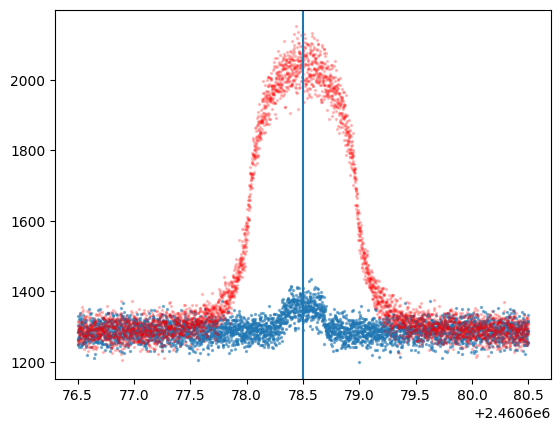

In [53]:
pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5)
pyplot.scatter(lcg_fit.times.jd, lcg_fit.flux_array, s=2, c='red', alpha=0.2)
pyplot.axvline(peak_time.jd)

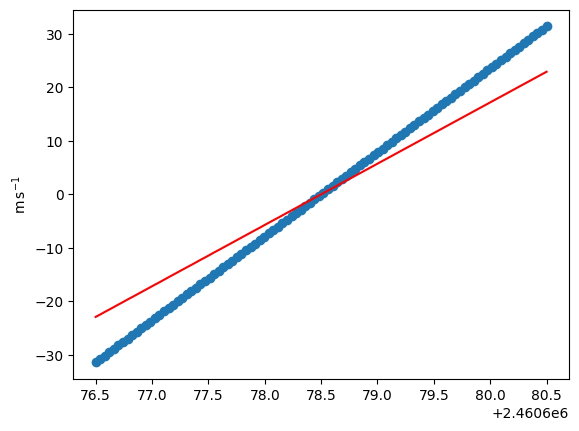

In [50]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

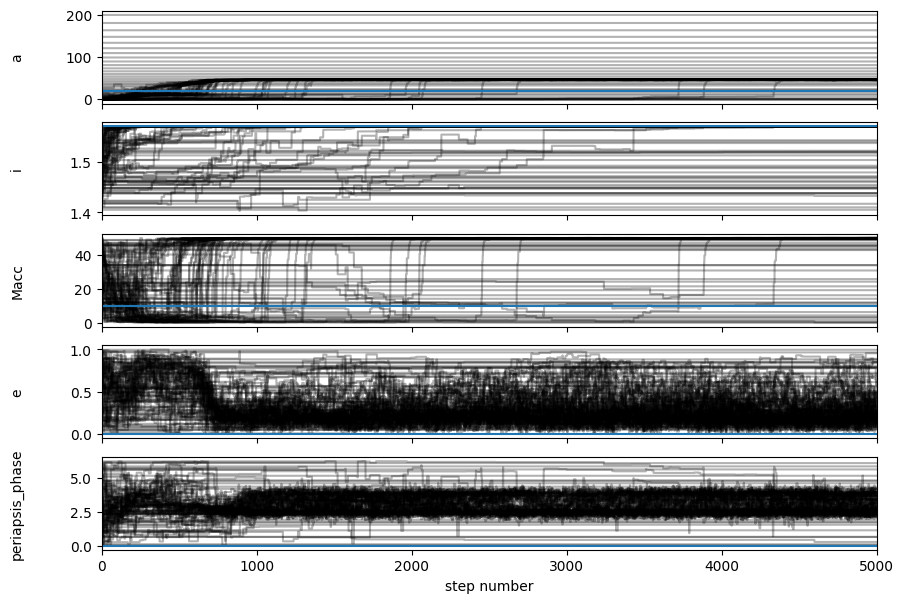

In [51]:
truths=[sls.a.value, sls.i.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]

from matplotlib import pyplot as plt
labels = ["a", "i", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.axhline(truths[i])
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

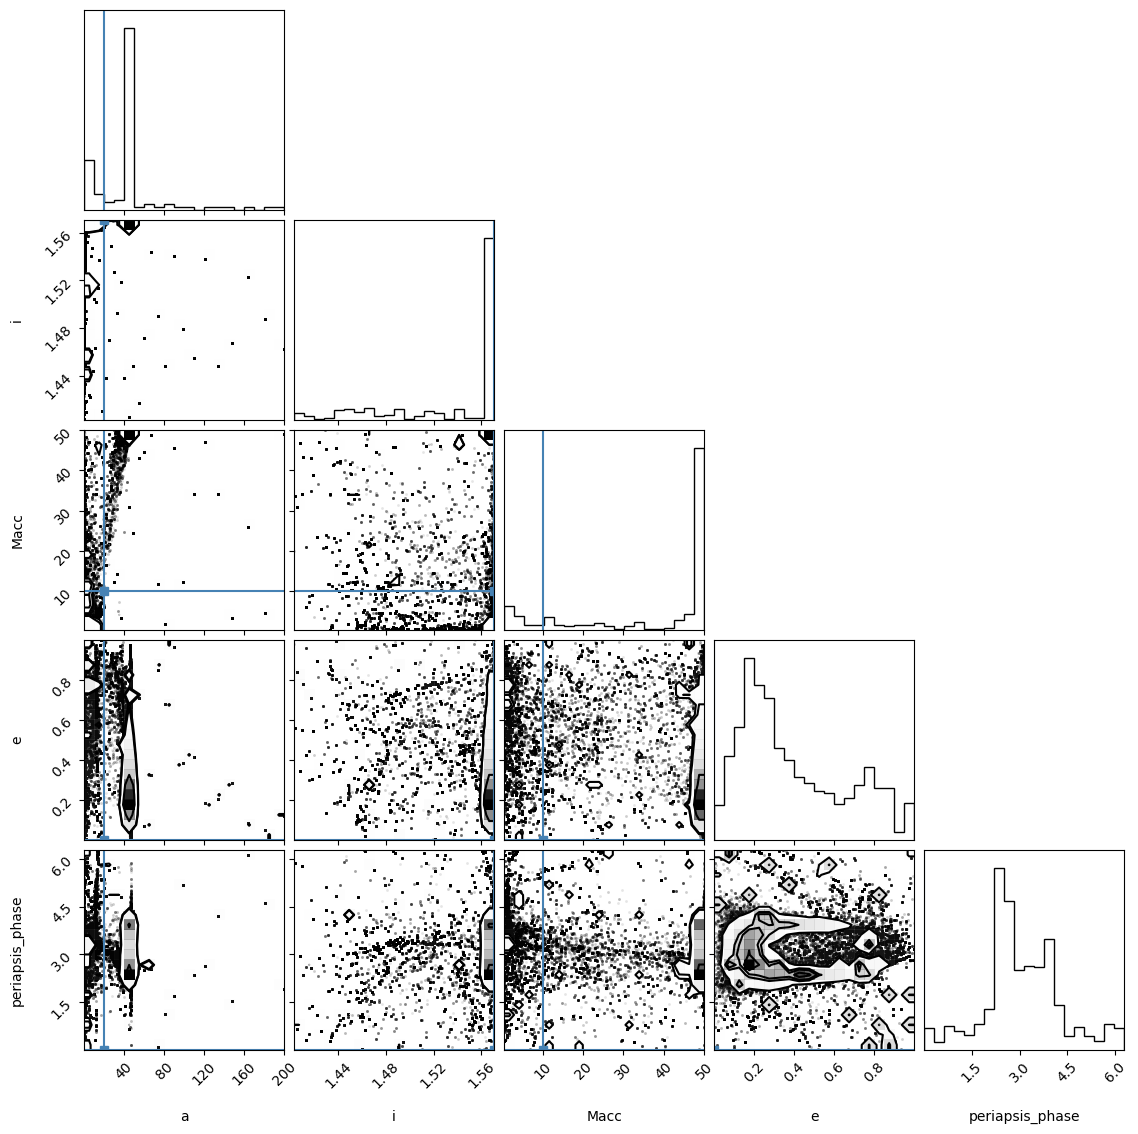

In [52]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=truths
)